# Proyecto Final - Análisis de tickets de soporte TI

- **Curso:** DataXperience - Ciencia de Datos (Grupo 1, Cuarto Ciclo Virtual 2026)
- **Estudiante:** Maicol Stiven Rodriguez Ortegon
- **Carrera:** Ingeniería en Sistemas

## Introducción

Para este proyecto escogí trabajar con datos de una mesa de ayuda de TI, o sea, los tickets que llegan cuando alguien tiene un problema con su computador, la red, el correo, etc. Lo elegí porque es un área muy relacionada con mi carrera y es donde muchos ingenieros de sistemas empiezan a trabajar.

La pregunta que quería responder es: **¿qué hace que un ticket se demore más en resolverse?** y si es posible predecir más o menos cuánto se va a demorar un ticket nuevo.

**Nota sobre los datos:** el archivo `tickets_soporte_ti_crudo.csv` es un dataset simulado que armé con la misma estructura que tienen los sistemas de tickets reales (como GLPI o Jira). Le dejé errores típicos (duplicados, fechas mal escritas, valores imposibles, etc.) para poder practicar la limpieza que vimos en el curso.

El notebook está dividido en las 3 etapas del proyecto:
1. Preparación y limpieza de los datos (Módulo 1)
2. Estadística descriptiva (Módulo 2)
3. Visualización, modelo y conclusiones (Módulo 3)

In [1]:
# importo las librerias que voy a usar
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", 20)
print("listo")

listo


# Etapa 1: Preparación de los datos

## Cargar el archivo
En Colab, al ejecutar esta celda sale un botón para subir el archivo `tickets_soporte_ti_crudo.csv` (está en la carpeta `datos` del repositorio).

In [2]:
ARCHIVO = "tickets_soporte_ti_crudo.csv"
rutas_posibles = [ARCHIVO, f"datos/{ARCHIVO}", f"../datos/{ARCHIVO}"]
ruta = next((r for r in rutas_posibles if os.path.exists(r)), None)

# si no encuentra el archivo lo pide para subirlo (esto es para colab)
if ruta is None:
    from google.colab import files
    print("Sube el archivo", ARCHIVO)
    files.upload()
    ruta = ARCHIVO

df_crudo = pd.read_csv(ruta)
print(f"Dataset cargado: {df_crudo.shape[0]} filas y {df_crudo.shape[1]} columnas")
df_crudo.head(10)

Dataset cargado: 1498 filas y 11 columnas


,id_ticket,fecha_apertura,categoria,prioridad,canal,area_solicitante,tecnico,reasignaciones,tiempo_resolucion_horas,sla_cumplido,satisfaccion
0,TK-10304,2025-03-16 03:57,Correo,Baja,Teléfono,Logística,TEC-06,2,34.3,Sí,2.0
1,TK-10816,2025-07-29 18:22,Software,Alta,Portal,Finanzas,TEC-05,0,"4,6",Sí,5.0
2,TK-10748,2025-07-11 23:39,Hardware,Media,Teléfono,Gerencia,TEC-01,1,22.0,Sí,3.0
3,TK-10333,2025-03-25 00:54,Hardware,Baja,Portal,Logística,TEC-03,1,37.6,Sí,NaN
4,TK-11391,2025-12-17 04:55,Accesos,Media,Teléfono,Operaciones,TEC-02,0,6.6,Sí,NaN
5,TK-11427,2025-12-27 17:16,Accesos,Media,Portal,Finanzas,TEC-02,0,12.2,Sí,3.0
6,TK-11318,2025-12-02 00:42,Red,Alta,Correo,Operaciones,TEC-05,0,26.4,No,5.0
7,TK-10698,2025-07-01 06:16,Accesos,Media,Chat,Ventas,TEC-06,1,16.7,Sí,NaN
8,TK-10657,2025-06-20 21:29,Hardware,Baja,Portal,Ventas,TEC-06,1,37.8,Sí,NaN
9,TK-11001,2025-09-11 16:23,Accesos,Crítica,Correo,Recursos Humanos,TEC-08,0,1.2,Sí,5.0


### Qué significa cada columna

| Columna | Qué es | Tipo de variable |
|---|---|---|
| id_ticket | código del ticket | identificador |
| fecha_apertura | fecha y hora en que se abrió | fecha |
| categoria | tipo de problema (Hardware, Software, Red, Accesos, Correo) | categórica nominal |
| prioridad | Baja, Media, Alta o Crítica | categórica ordinal |
| canal | por dónde llegó (Portal, Correo, Teléfono, Chat) | categórica nominal |
| area_solicitante | área de la empresa que lo pidió | categórica nominal |
| tecnico | técnico asignado | categórica nominal |
| reasignaciones | cuántas veces se pasó a otro técnico | numérica discreta |
| tiempo_resolucion_horas | horas que tomó resolverlo (es la variable que quiero analizar) | numérica continua |
| sla_cumplido | si se resolvió dentro del tiempo acordado (Sí/No) | booleana |
| satisfaccion | calificación del usuario de 1 a 5 | ordinal |

## Exploración inicial
Primero miro con `info()` los tipos de datos y cuántos valores no nulos hay.

In [3]:
df_crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 1498 entries, 0 to 1497
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_ticket                1498 non-null   str    
 1   fecha_apertura           1498 non-null   str    
 2   categoria                1498 non-null   str    
 3   prioridad                1498 non-null   str    
 4   canal                    1498 non-null   str    
 5   area_solicitante         1468 non-null   str    
 6   tecnico                  1498 non-null   str    
 7   reasignaciones           1498 non-null   int64  
 8   tiempo_resolucion_horas  1453 non-null   str    
 9   sla_cumplido             1498 non-null   str    
 10  satisfaccion             1289 non-null   float64
dtypes: float64(1), int64(1), str(9)
memory usage: 128.9 KB


Aquí ya se ve un problema: `tiempo_resolucion_horas` debería ser numérica pero pandas la leyó como texto. Eso quiere decir que hay valores raros en esa columna. La fecha también está como texto. Además hay nulos en área, tiempo y satisfacción.

In [4]:
# nulos y duplicados
print("Nulos por columna:")
print(df_crudo.isnull().sum())
print("\nFilas duplicadas:", df_crudo.duplicated().sum())

Nulos por columna:
id_ticket                    0
fecha_apertura               0
categoria                    0
prioridad                    0
canal                        0
area_solicitante            30
tecnico                      0
reasignaciones               0
tiempo_resolucion_horas     45
sla_cumplido                 0
satisfaccion               209
dtype: int64

Filas duplicadas: 48


In [5]:
# reviso los valores de las columnas de texto para ver si estan bien escritos
for col in ["categoria", "prioridad", "sla_cumplido"]:
    print(f"{col}: {sorted(df_crudo[col].unique())}\n")

categoria: [' Accesos ', ' Correo ', ' Hardware ', ' Red ', ' Software ', 'ACCESOS', 'Accesos', 'CORREO', 'Correo', 'HARDWARE', 'Hardware', 'RED', 'Red', 'SOFTWARE', 'Software', 'accesos', 'correo', 'hardware', 'red', 'software']

prioridad: ['ALTA', 'Alta', 'BAJA', 'Baja', 'CRITICA', 'Critica', 'Crítica', 'MEDIA', 'Media', 'alta', 'baja', 'crítica', 'media']

sla_cumplido: ['NO', 'No', 'Sí', 'si']



In [6]:
# reviso por que el tiempo quedo como texto
tiempo_txt = df_crudo["tiempo_resolucion_horas"].dropna().astype(str)
print("Valores con coma:", tiempo_txt.str.contains(",").sum(), "ejemplo:", tiempo_txt[tiempo_txt.str.contains(",")].head(3).tolist())

tiempo_num = pd.to_numeric(tiempo_txt.str.replace(",", "."), errors="coerce")
print("Tiempos negativos:", (tiempo_num < 0).sum())
print("Tiempos = 9999:", (tiempo_num == 9999).sum())

print("\nValores de satisfaccion:", sorted(pd.to_numeric(df_crudo["satisfaccion"], errors="coerce").dropna().unique()))
print("Fechas con formato dd/mm/aaaa:", df_crudo["fecha_apertura"].str.contains("/").sum())

Valores con coma: 55 ejemplo: ['4,6', '19,0', '9,1']
Tiempos negativos: 11
Tiempos = 9999: 8

Valores de satisfaccion: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(9.0)]
Fechas con formato dd/mm/aaaa: 74


### Problemas que encontré

- Hay **48 filas duplicadas**.
- La categoría y la prioridad están escritas de muchas formas (`red`, `RED`, ` Red `, `Critica` sin tilde...).
- En `sla_cumplido` hay `si` y `NO` mezclados con `Sí` y `No`.
- Las fechas tienen dos formatos diferentes.
- Algunos tiempos tienen coma decimal (`14,5`), por eso la columna quedó como texto.
- Hay tiempos negativos, que no tienen sentido, y tiempos de 9999, que parece un código de "sin dato".
- En satisfacción hay valores de 0 y 9, pero la escala es de 1 a 5.

### Qué decidí hacer con cada uno
- Duplicados: eliminarlos.
- Textos: quitar espacios y dejar todo con el mismo formato.
- Fechas: convertirlas a `datetime` probando los dos formatos.
- Tiempo: cambiar la coma por punto, pasarlo a número y poner como nulo los negativos y los 9999.
- Tickets sin tiempo: los eliminé, porque el tiempo es la variable principal y si lo relleno con un promedio estaría inventando datos.
- Satisfacción: los valores fuera de 1 a 5 los dejé como nulo. Los nulos de satisfacción no los rellené porque son personas que no contestaron la encuesta, pero el resto del ticket sí sirve.
- Área vacía: la llené con "Sin registro".

## Limpieza
Trabajo sobre una copia para no dañar los datos originales.

In [7]:
df = df_crudo.copy()
filas_iniciales = len(df)

# 1. duplicados
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {filas_iniciales - len(df)}")

# 2. arreglar textos
df["categoria"] = df["categoria"].str.strip().str.title()
mapa_prioridad = {"baja": "Baja", "media": "Media", "alta": "Alta", "crítica": "Crítica", "critica": "Crítica"}
df["prioridad"] = df["prioridad"].str.strip().str.lower().map(mapa_prioridad)
df["sla_cumplido"] = df["sla_cumplido"].str.strip().str.lower().map({"sí": "Sí", "si": "Sí", "no": "No"})

# 3. fechas (hay dos formatos, convierto cada uno y los junto)
f1 = pd.to_datetime(df["fecha_apertura"], format="%Y-%m-%d %H:%M", errors="coerce")
f2 = pd.to_datetime(df["fecha_apertura"], format="%d/%m/%Y %H:%M", errors="coerce")
df["fecha_apertura"] = f1.fillna(f2)

# 4. tiempo: coma por punto y a numero
df["tiempo_resolucion_horas"] = pd.to_numeric(
    df["tiempo_resolucion_horas"].astype(str).str.replace(",", "."), errors="coerce")
invalidos = (df["tiempo_resolucion_horas"] < 0) | (df["tiempo_resolucion_horas"] == 9999)
df.loc[invalidos, "tiempo_resolucion_horas"] = np.nan
print(f"Tiempos invalidos (negativos o 9999): {invalidos.sum()}")

# 5. quito los tickets que quedaron sin tiempo
sin_tiempo = df["tiempo_resolucion_horas"].isnull().sum()
df = df.dropna(subset=["tiempo_resolucion_horas"]).reset_index(drop=True)
print(f"Filas eliminadas sin tiempo: {sin_tiempo}")

# 6. satisfaccion solo de 1 a 5
df["satisfaccion"] = pd.to_numeric(df["satisfaccion"], errors="coerce")
df.loc[~df["satisfaccion"].between(1, 5), "satisfaccion"] = np.nan
df["satisfaccion"] = df["satisfaccion"].astype("Int64")

# 7. area vacia
df["area_solicitante"] = df["area_solicitante"].fillna("Sin registro")

# la prioridad tiene un orden, entonces la dejo como categoria ordenada
df["prioridad"] = pd.Categorical(df["prioridad"], categories=["Baja", "Media", "Alta", "Crítica"], ordered=True)

# columna nueva con el mes
df["mes"] = df["fecha_apertura"].dt.month

print(f"\nQuedaron {len(df)} de {filas_iniciales} filas ({len(df)/filas_iniciales:.1%})")

Duplicados eliminados: 48
Tiempos invalidos (negativos o 9999): 19
Filas eliminadas sin tiempo: 62

Quedaron 1388 de 1498 filas (92.7%)


## Verifico cómo quedó

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1388 entries, 0 to 1387
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   id_ticket                1388 non-null   str           
 1   fecha_apertura           1388 non-null   datetime64[us]
 2   categoria                1388 non-null   str           
 3   prioridad                1388 non-null   category      
 4   canal                    1388 non-null   str           
 5   area_solicitante         1388 non-null   str           
 6   tecnico                  1388 non-null   str           
 7   reasignaciones           1388 non-null   int64         
 8   tiempo_resolucion_horas  1388 non-null   float64       
 9   sla_cumplido             1388 non-null   str           
 10  satisfaccion             1188 non-null   Int64         
 11  mes                      1388 non-null   int32         
dtypes: Int64(1), category(1), datetime64[us](1), 

In [9]:
print("Nulos que quedan:\n", df.isnull().sum()[df.isnull().sum() > 0])
for col in ["categoria", "prioridad", "sla_cumplido"]:
    print(f"\n{col}: {list(df[col].unique())}")

Nulos que quedan:
 satisfaccion    200
dtype: int64

categoria: ['Correo', 'Software', 'Hardware', 'Accesos', 'Red']

prioridad: ['Baja', 'Alta', 'Media', 'Crítica']

sla_cumplido: ['Sí', 'No']


In [10]:
# tabla resumen del dataset limpio
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(),
    "nulos": df.isnull().sum(),
    "ejemplo": df.iloc[0],
})
resumen

,tipo,valores_unicos,nulos,ejemplo
id_ticket,str,1388,0,TK-10304
fecha_apertura,datetime64[us],1387,0,2025-03-16 03:57:00
categoria,str,5,0,Correo
prioridad,category,4,0,Baja
canal,str,4,0,Teléfono
area_solicitante,str,7,0,Logística
tecnico,str,8,0,TEC-06
reasignaciones,int64,6,0,2
tiempo_resolucion_horas,float64,481,0,34.3
sla_cumplido,str,2,0,Sí


In [11]:
# guardo el dataset limpio
df.to_csv("tickets_soporte_ti_limpio.csv", index=False)
print("guardado")

guardado


**Resumen de la etapa 1:** empecé con 1.498 filas y terminé con 1.388 (me quedé con el 92,7% de los datos). Eliminé 48 duplicados, arreglé los textos, las fechas y las comas, encontré 19 tiempos que no tenían sentido y quité 62 tickets que no tenían tiempo. Los 200 tickets sin encuesta de satisfacción los dejé, porque el resto de su información sí sirve.

# Etapa 2: Estadística descriptiva

## Medidas de tendencia central y dispersión del tiempo de resolución

In [12]:
t = df["tiempo_resolucion_horas"]

estadisticas = pd.Series({
    "Media": t.mean(),
    "Mediana": t.median(),
    "Moda": t.round(0).mode()[0],   # redondeo a horas enteras porque con decimales casi no se repiten
    "Mínimo": t.min(),
    "Máximo": t.max(),
    "Rango": t.max() - t.min(),
    "Varianza": t.var(),
    "Desviación estándar": t.std(),
    "Coef. de variación (%)": t.std() / t.mean() * 100,
    "Asimetría": t.skew(),
}).round(2)
estadisticas.to_frame("tiempo_resolucion_horas")

,tiempo_resolucion_horas
Media,24.65
Mediana,22.50
Moda,28.00
Mínimo,0.30
Máximo,109.60
Rango,109.30
Varianza,240.60
Desviación estándar,15.51
Coef. de variación (%),62.93
Asimetría,1.77


Lo que veo en estos resultados:

- En promedio un ticket se demora **24,7 horas**, pero la **mediana es 22,5 horas**, o sea que la mitad de los tickets se resuelve en menos de un día.
- La media es mayor que la mediana y la asimetría es positiva (1,77). Eso quiere decir que la distribución está sesgada a la derecha: hay unos pocos tickets que se demoran muchísimo y suben el promedio. Por eso me parece que la mediana representa mejor el tiempo "normal" de un ticket.
- La desviación estándar es de 15,5 horas y el coeficiente de variación de 63%, que es bastante alto. Los tiempos cambian mucho de un ticket a otro.
- El rango va desde 0,3 horas hasta 109,6 horas (más de 4 días).

## Comparación por prioridad y por categoría

In [13]:
por_prioridad = df.groupby("prioridad", observed=True).agg(
    tickets=("id_ticket", "count"),
    media_horas=("tiempo_resolucion_horas", "mean"),
    mediana_horas=("tiempo_resolucion_horas", "median"),
    desv_horas=("tiempo_resolucion_horas", "std"),
    sla_cumplido_pct=("sla_cumplido", lambda s: (s == "Sí").mean() * 100),
    satisfaccion_media=("satisfaccion", "mean"),
).round(1)
por_prioridad

,tickets,media_horas,mediana_horas,desv_horas,sla_cumplido_pct,satisfaccion_media
prioridad,,,,,,
Baja,417,32.8,30.1,13.8,92.3,3.3
Media,552,25.5,22.6,14.3,54.7,3.5
Alta,297,16.0,13.4,12.6,25.9,3.9
Crítica,122,14.1,9.0,15.8,23.0,4.0


In [14]:
por_categoria = df.groupby("categoria").agg(
    tickets=("id_ticket", "count"),
    media_horas=("tiempo_resolucion_horas", "mean"),
    mediana_horas=("tiempo_resolucion_horas", "median"),
    desv_horas=("tiempo_resolucion_horas", "std"),
    reasignaciones_media=("reasignaciones", "mean"),
).round(1).sort_values("media_horas", ascending=False)
por_categoria

,tickets,media_horas,mediana_horas,desv_horas,reasignaciones_media
categoria,,,,,
Hardware,328,32.0,28.7,18.3,0.8
Red,242,25.4,25.2,12.3,0.8
Software,403,23.0,21.7,13.6,0.8
Correo,167,20.7,19.4,14.1,0.8
Accesos,248,19.5,18.4,14.4,0.8


Lo que encontré:

- Los tickets urgentes sí se atienden más rápido (los Críticos tienen mediana de 9 horas y los de prioridad Baja de 30 horas). **Pero** lo que más me llamó la atención es el SLA: los de prioridad Baja cumplen el 92% de las veces, mientras que los de prioridad Alta solo el 26% y los Críticos el 23%. Es decir, los tickets más importantes son los que menos cumplen el tiempo acordado (8 y 4 horas).
- Por categoría, Hardware es la que más se demora (32 horas en promedio) y también la que más varía. Le sigue Red con 25 horas. Accesos y Correo son las más rápidas, alrededor de 20 horas.
- Las reasignaciones promedio son casi iguales en todas las categorías (0,8), entonces que Hardware sea más lento no es por las reasignaciones. Supongo que es porque toca revisar equipos físicos o esperar repuestos.
- Algo curioso: los usuarios con tickets de prioridad Baja son los menos satisfechos (3,3 de 5), seguramente porque son los que más esperan.

## Outliers
Uso el método del rango intercuartílico (IQR): todo lo que esté por encima de Q3 + 1.5*IQR lo tomo como atípico.

Q1 = 14.9 h, Q3 = 31.1 h, IQR = 16.2 h, limite superior = 55.4 h
Tickets atipicos: 52 (3.7%)

Reasignaciones promedio en atipicos: 1.1 - en el resto: 0.79

% de cada categoria dentro de los atipicos:
categoria
Hardware    53.8
Software    19.2
Accesos     13.5
Correo       7.7
Red          5.8
Name: proportion, dtype: float64

% de Hardware en todo el dataset: 23.6


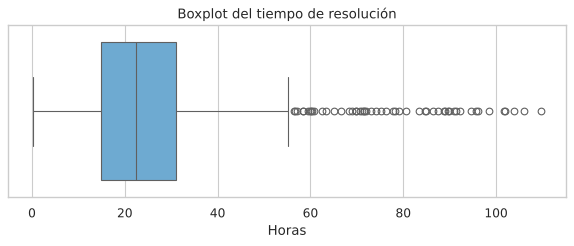

In [15]:
q1, q3 = t.quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
outliers = df[t > limite_sup]
print(f"Q1 = {q1:.1f} h, Q3 = {q3:.1f} h, IQR = {iqr:.1f} h, limite superior = {limite_sup:.1f} h")
print(f"Tickets atipicos: {len(outliers)} ({len(outliers)/len(df):.1%})")
print("\nReasignaciones promedio en atipicos:", round(outliers["reasignaciones"].mean(), 2),
      "- en el resto:", round(df.loc[t <= limite_sup, "reasignaciones"].mean(), 2))
print("\n% de cada categoria dentro de los atipicos:")
print((outliers["categoria"].value_counts(normalize=True) * 100).round(1))
print("\n% de Hardware en todo el dataset:", round((df["categoria"] == "Hardware").mean() * 100, 1))

fig, ax = plt.subplots(figsize=(9, 2.8))
sns.boxplot(x=t, ax=ax, color="#5DADE2")
ax.set_title("Boxplot del tiempo de resolución")
ax.set_xlabel("Horas")
plt.show()

Salieron 52 tickets atípicos (3,7%) que se demoraron más de 55 horas. Decidí **no eliminarlos**, porque no son errores, son tickets reales que de verdad se demoraron mucho y son justamente los que más afectan a los usuarios.

Algo interesante es que el 54% de los atípicos son de Hardware, cuando Hardware es solo el 24% de todos los tickets. Puede ser por tickets que quedan esperando un repuesto o a un proveedor.

## Correlación entre variables numéricas

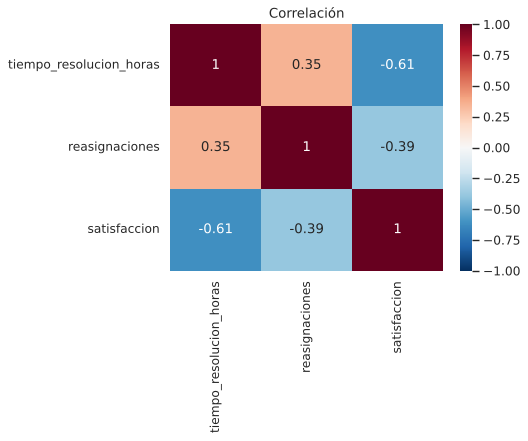

,tiempo_resolucion_horas,reasignaciones,satisfaccion
tiempo_resolucion_horas,1.00,0.35,-0.61
reasignaciones,0.35,1.00,-0.39
satisfaccion,-0.61,-0.39,1.00


In [16]:
corr = df[["tiempo_resolucion_horas", "reasignaciones", "satisfaccion"]].astype(float).corr().round(2)
plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación")
plt.show()
corr

### Hipótesis
Con estos resultados planteo estas hipótesis:

1. **Entre más reasignaciones, más se demora el ticket.** La correlación es de 0,35 (moderada) y en el gráfico se ve que pasa de unas 19 horas sin reasignaciones a unas 49 horas con 5.
2. **Entre más se demora el ticket, más baja la satisfacción.** La correlación es de -0,61, la más fuerte de todas.
3. **Hardware es la categoría más lenta y la que tiene más casos extremos.**
4. **El SLA de los tickets urgentes no es realista con el equipo actual**, porque solo 1 de cada 4 lo cumple.

Hay que tener en cuenta que correlación no significa causalidad, entonces estas hipótesis habría que comprobarlas con más datos.

# Etapa 3: Visualización, modelo y conclusiones

## Gráficos

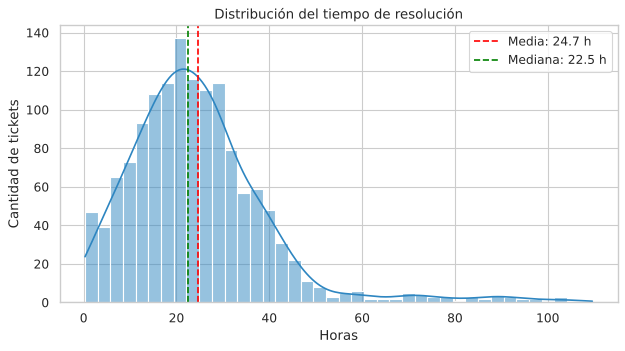

In [17]:
# grafico 1: distribucion del tiempo
plt.figure()
sns.histplot(t, bins=40, color="#2E86C1", kde=True)
plt.axvline(t.mean(), color="red", linestyle="--", label=f"Media: {t.mean():.1f} h")
plt.axvline(t.median(), color="green", linestyle="--", label=f"Mediana: {t.median():.1f} h")
plt.title("Distribución del tiempo de resolución")
plt.xlabel("Horas"); plt.ylabel("Cantidad de tickets")
plt.legend(); plt.show()

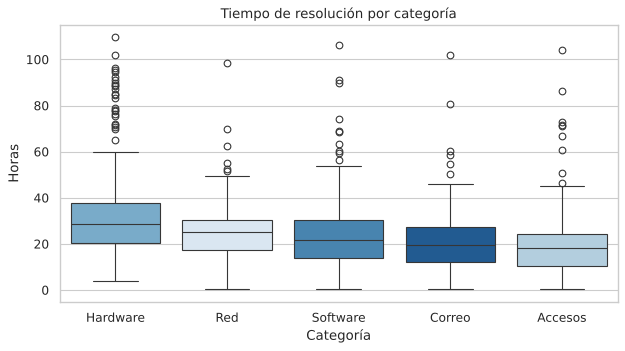

In [18]:
# grafico 2: tiempo por categoria
orden = por_categoria.index
plt.figure()
sns.boxplot(data=df, x="categoria", y="tiempo_resolucion_horas", order=orden, hue="categoria", palette="Blues_r", legend=False)
plt.title("Tiempo de resolución por categoría")
plt.xlabel("Categoría"); plt.ylabel("Horas")
plt.show()

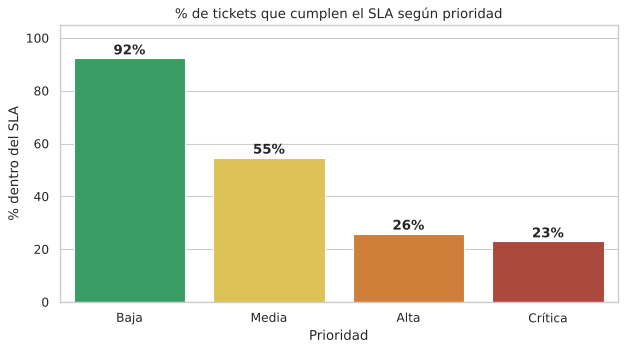

In [19]:
# grafico 3: % de cumplimiento del SLA por prioridad
plt.figure()
etiquetas = por_prioridad.index.astype(str)
ax = sns.barplot(x=etiquetas, y=por_prioridad["sla_cumplido_pct"].values, hue=etiquetas,
                 palette=["#27AE60", "#F4D03F", "#E67E22", "#C0392B"], legend=False)
for i, v in enumerate(por_prioridad["sla_cumplido_pct"]):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontweight="bold")
plt.title("% de tickets que cumplen el SLA según prioridad")
plt.xlabel("Prioridad"); plt.ylabel("% dentro del SLA"); plt.ylim(0, 105)
plt.show()

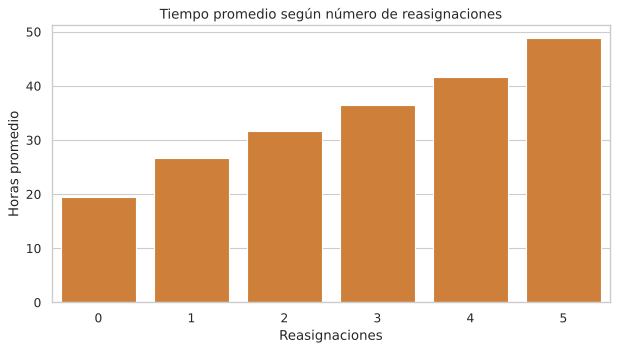

In [20]:
# grafico 4: reasignaciones vs tiempo
plt.figure()
sns.barplot(data=df, x="reasignaciones", y="tiempo_resolucion_horas", color="#E67E22", errorbar=None)
plt.title("Tiempo promedio según número de reasignaciones")
plt.xlabel("Reasignaciones"); plt.ylabel("Horas promedio")
plt.show()

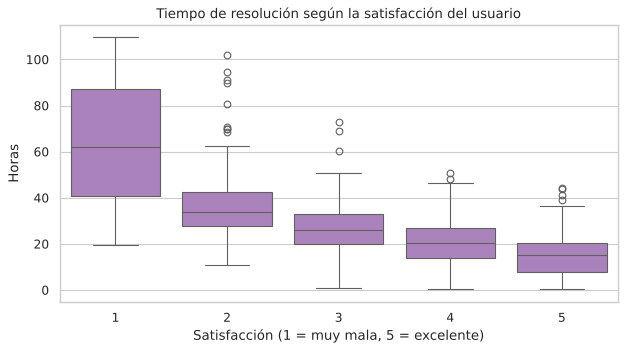

In [21]:
# grafico 5: tiempo vs satisfaccion
plt.figure()
sns.boxplot(data=df.dropna(subset=["satisfaccion"]), x="satisfaccion", y="tiempo_resolucion_horas", color="#AF7AC5")
plt.title("Tiempo de resolución según la satisfacción del usuario")
plt.xlabel("Satisfacción (1 = muy mala, 5 = excelente)"); plt.ylabel("Horas")
plt.show()

## Modelo: regresión lineal

Quiero predecir `tiempo_resolucion_horas` usando la prioridad, la categoría, el canal y las reasignaciones. Como la regresión lineal solo trabaja con números, convierto las variables categóricas con `pd.get_dummies` (con `drop_first=True` para no repetir información).

Separo 80% de los datos para entrenar y 20% para probar.

In [22]:
X = pd.get_dummies(df[["prioridad", "categoria", "canal", "reasignaciones"]],
                   columns=["prioridad", "categoria", "canal"], drop_first=True, dtype=int)
y = df["tiempo_resolucion_horas"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {len(X_train)}, prueba: {len(X_test)}")
print("Variables:", list(X.columns))

modelo = LinearRegression()
modelo.fit(X_train, y_train)

Entrenamiento: 1110, prueba: 278
Variables: ['reasignaciones', 'prioridad_Media', 'prioridad_Alta', 'prioridad_Crítica', 'categoria_Correo', 'categoria_Hardware', 'categoria_Red', 'categoria_Software', 'canal_Correo', 'canal_Portal', 'canal_Teléfono']


LinearRegression()

In [23]:
pred = modelo.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

# validacion cruzada con 5 particiones para ver si el resultado es estable
cv = cross_val_score(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")

print(f"MAE:  {mae:.2f} horas")
print(f"RMSE: {rmse:.2f} horas")
print(f"R2:   {r2:.2f}")
print(f"R2 validacion cruzada: {cv.mean():.2f} +/- {cv.std():.2f}")

MAE:  6.92 horas
RMSE: 10.73 horas
R2:   0.47
R2 validacion cruzada: 0.41 +/- 0.03


Intercepto: 21.7 h (ticket de prioridad Baja, Accesos, por Chat y sin reasignaciones)



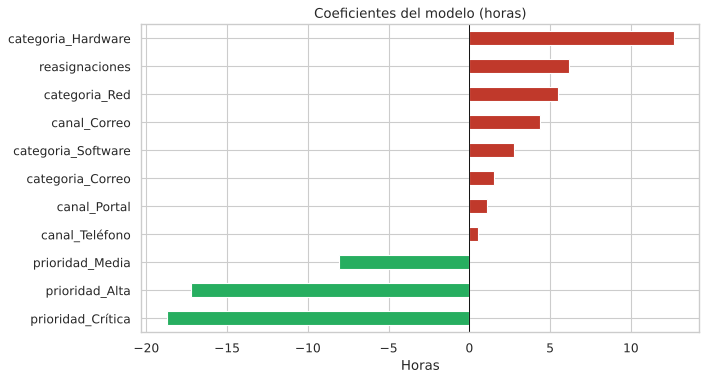

,horas
prioridad_Crítica,-18.74
prioridad_Alta,-17.22
prioridad_Media,-8.09
canal_Teléfono,0.51
canal_Portal,1.06
categoria_Correo,1.52
categoria_Software,2.74
canal_Correo,4.37
categoria_Red,5.50
reasignaciones,6.18


In [24]:
# coeficientes: cuantas horas suma o resta cada variable
coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
print(f"Intercepto: {modelo.intercept_:.1f} h (ticket de prioridad Baja, Accesos, por Chat y sin reasignaciones)\n")

plt.figure(figsize=(9, 5))
colores = ["#C0392B" if v > 0 else "#27AE60" for v in coeficientes]
coeficientes.plot(kind="barh", color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes del modelo (horas)")
plt.xlabel("Horas")
plt.show()
coeficientes.round(2).to_frame("horas")

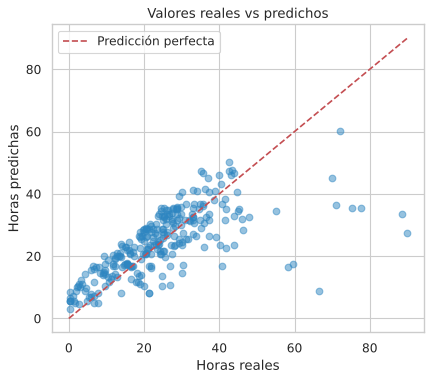

In [25]:
# grafico real vs predicho
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred, alpha=0.5, color="#2E86C1")
lim = [0, max(y_test.max(), pred.max())]
plt.plot(lim, lim, "r--", label="Predicción perfecta")
plt.xlabel("Horas reales"); plt.ylabel("Horas predichas")
plt.title("Valores reales vs predichos")
plt.legend(); plt.show()

In [26]:
# prueba con un ticket nuevo
nuevo = pd.DataFrame(0, index=[0], columns=X.columns)
nuevo["categoria_Hardware"] = 1
nuevo["prioridad_Alta"] = 1
nuevo["canal_Correo"] = 1
nuevo["reasignaciones"] = 1
print(f"Ticket de Hardware, prioridad Alta, por correo y 1 reasignacion: {modelo.predict(nuevo)[0]:.1f} horas aprox.")

Ticket de Hardware, prioridad Alta, por correo y 1 reasignacion: 27.7 horas aprox.


### Qué tan bueno es el modelo
- El **R² es 0,47**, entonces el modelo explica casi la mitad de la variación del tiempo. No es perfecto, pero tiene sentido, porque hay cosas que influyen y que no están en los datos (por ejemplo si hay que esperar un repuesto o si el usuario no está disponible).
- El **MAE es 6,9 horas**: en promedio la predicción se equivoca en unas 7 horas. El RMSE (10,7 h) es más alto porque los tickets atípicos generan errores grandes.
- En la **validación cruzada** el R² da 0,41 y casi no cambia entre particiones (±0,03), así que el modelo es estable y no parece tener overfitting.
- Viendo los coeficientes:
  - Un ticket de Hardware suma unas **12,7 horas** comparado con uno de Accesos.
  - Cada reasignación suma unas **6,2 horas**.
  - Si llega por correo se demora unas **4,4 horas** más que por chat.
  - Las prioridades Alta y Crítica restan entre 17 y 19 horas, porque se atienden primero.
- Por ejemplo, para un ticket de Hardware, prioridad Alta, que llega por correo y se reasigna una vez, el modelo estima unas 27,7 horas.

# Conclusiones

En resumen, el área de soporte resuelve la mitad de los tickets en menos de un día, pero los tiempos varían mucho. El problema más grande que encontré es que **los tickets urgentes son los que menos cumplen el SLA**.

Las principales causas que muestran los datos son:
- Los tickets de **Hardware**, que son los más lentos y tienen la mayoría de casos extremos.
- Las **reasignaciones**: cada vez que un ticket pasa a otro técnico se pierden unas 6 horas.
- El **correo** como canal, que es el más lento.

Y esto afecta directamente a los usuarios, porque entre más esperan, peor califican el servicio.

Lo que yo le recomendaría al área de TI:
- Asignar bien los tickets desde el principio según la categoría, para reducir las reasignaciones.
- Tener repuestos disponibles y un técnico dedicado a Hardware.
- Pedirle a los usuarios que usen el portal o el chat en lugar del correo.
- Revisar el SLA de los tickets Alta y Crítica: o se refuerza el equipo o se ponen tiempos más realistas.

## Cómo lo aplicaría en mi carrera
Como ingeniero de sistemas esto lo podría aplicar en una mesa de ayuda o en un área de soporte:
- Conectar el modelo con la herramienta de tickets (GLPI, Jira Service Management, ServiceNow) para que cuando se abra un ticket se estime cuánto se va a demorar y avise si es probable que no cumpla el SLA.
- Hacer un dashboard en Power BI para hacer seguimiento al cumplimiento del SLA, los tiempos por categoría y la satisfacción.
- Usar estos datos para decidir cuántos técnicos se necesitan y en qué especialidad.
- Automatizar los tickets más repetitivos, como los de Accesos (por ejemplo, el desbloqueo de contraseñas).

## Lo que aprendí
- Que los datos casi nunca vienen limpios y que la limpieza es una parte muy importante. Si no hubiera quitado los 9999, el promedio habría salido totalmente mal.
- Que la media no siempre es la mejor medida; cuando los datos están sesgados la mediana dice más.
- Que un modelo no tiene que ser perfecto para ser útil, pero hay que explicar sus limitaciones.
- Que los gráficos ayudan mucho a explicar los resultados a alguien que no sabe de datos.